# 24ADI306 Deep Learning — Self-Learning Assignment 1
## Exploring Word Representations: From Traditional Word Embeddings to Transformers

**Student:** Saravanan P (24BAD105)  
**Department:** Artificial Intelligence and Data Science  




## 1. Install and import libraries

TensorFlow is normally available in Colab. The cell installs Gensim and Hugging Face Transformers if needed. If a package was already imported before installation, use **Runtime → Restart session** and run the notebook from the top.

In [1]:
%pip -q install "gensim>=4.3.3" "transformers>=4.40.0,<5"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 27.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

import scipy.linalg
# Compatibility patch for environments where SciPy no longer exposes triu.
if not hasattr(scipy.linalg, "triu"):
    scipy.linalg.triu = np.triu

from gensim.models import Word2Vec, FastText
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

Python: 3.13.16
TensorFlow: 2.21.0
NumPy: 2.1.3


## 2. Prepare a common sample text dataset

Each sentence belongs to one of six broad topics. The corpus contains contextual examples for the word **bank** (financial institution and river edge). Text is lowercased and tokenized for Word2Vec/FastText.

In [3]:
corpus = [
    # Technology
    "python code helps students build software applications",
    "computer systems process data using algorithms and programs",
    "machine learning models learn patterns from training data",
    "the neural network classifies text and predicts a label",
    "software developers debug code and test a computer program",
    "data science combines statistics programming and visualization",
    "the algorithm processes information stored in a database",
    "a computer uses memory and a processor to run software",
    "artificial intelligence uses data to make useful predictions",
    "programming students practice python and solve coding problems",
    "a digital system can store retrieve and analyze information",
    "the model improves when it is trained with more examples",
    # Sports
    "basketball players practice shooting passing and defending",
    "the coach trains the team before the basketball game",
    "athletes exercise daily to improve strength speed and fitness",
    "the player scored points on the basketball court",
    "football teams use tactics to win important matches",
    "a coach studies game performance and player statistics",
    "training helps an athlete build muscle and endurance",
    "the team celebrated after winning the final game",
    "sports improve physical health teamwork and discipline",
    "players practice basketball drills at the sports ground",
    "the match referee checks the score and follows the rules",
    "a player needs practice focus and fitness to perform well",
    # Health
    "exercise and a balanced diet support good health",
    "the doctor examines a patient at the hospital",
    "protein helps muscle recovery after strength training",
    "fitness improves when people sleep well and exercise regularly",
    "the nurse gives medicine according to the doctor's advice",
    "healthy food provides energy vitamins and minerals",
    "a patient visits the clinic for a medical checkup",
    "strength training can build muscle and improve endurance",
    "health professionals explain treatment and recovery plans",
    "water and nutritious meals support everyday fitness",
    "regular exercise can reduce stress and support wellness",
    "medical research studies disease prevention and patient care",
    # Finance and bank meaning 1
    "the customer deposited money into a bank account",
    "a bank offers savings accounts loans and financial services",
    "the banker checked the account balance and interest rate",
    "people save money in a bank for future expenses",
    "the business applied for a loan from the local bank",
    "online banking lets customers transfer money securely",
    "a financial adviser explains credit savings and investment",
    "the customer withdrew cash from the bank yesterday",
    # Nature and bank meaning 2
    "the river bank was covered with grass and small trees",
    "children sat on the bank of the river near the water",
    "the river flows past a forest and a green valley",
    "trees and plants grow in healthy soil near the river",
    "the mountain stream carries fresh water through the forest",
    "birds and animals live in habitats across the natural world",
    "the river bank becomes muddy after heavy rain",
    "nature includes rivers mountains forests plants and animals",
    # Education
    "students attend college classes and complete assignments",
    "the teacher explains a concept before the examination",
    "learning new skills helps students prepare for their careers",
    "the university library provides books and study materials",
    "a student writes notes while the professor teaches a lesson",
    "the class uses examples to understand a difficult topic",
    "students practice questions before the final exam",
    "education combines reading discussion practice and assessment",
    # Additional cross-topic context
    "students use python to analyze sports and health data",
    "a fitness tracker records data about exercise and sleep",
    "a bank uses computer systems to protect customer information",
    "machine learning can help a hospital organize medical records",
    "a student learns finance by reading examples and solving problems",
    "the coach uses statistics to analyze team performance",
    "scientists use data to study rivers and climate patterns",
    "software helps a college organize student records",
]


def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

sentences = [tokenize(text) for text in corpus]
print(f"Number of documents: {len(corpus)}")
print(f"Total tokens: {sum(len(s) for s in sentences)}")
print(f"Unique tokens: {len(set(w for s in sentences for w in s))}")
print("Example:", corpus[0])

Number of documents: 68
Total tokens: 575
Unique tokens: 300
Example: python code helps students build software applications


## 3. Traditional representation: TF-IDF

TF-IDF represents each document using weighted term frequencies. A word gets a larger weight when it is frequent in a document but less common across the whole corpus. To compare words, this experiment treats each word's TF-IDF scores across all documents as its vector and ranks neighbours using cosine similarity.

In [4]:
tfidf = TfidfVectorizer(ngram_range=(1, 1), lowercase=True, stop_words="english")
X_tfidf = tfidf.fit_transform(corpus)
terms = tfidf.get_feature_names_out()
# A word vector is its TF-IDF weight across documents.
term_vectors = X_tfidf.T
term_to_idx = {term: i for i, term in enumerate(terms)}
print("TF-IDF document matrix shape:", X_tfidf.shape)
print("Vocabulary size:", len(terms))

def most_similar_tfidf(query, topn=5):
    query = query.lower()
    if query not in term_to_idx:
        print(f"'{query}' is not in the TF-IDF vocabulary.")
        return []
    sims = cosine_similarity(term_vectors[term_to_idx[query]], term_vectors).ravel()
    sims[term_to_idx[query]] = -1
    best = np.argsort(sims)[::-1][:topn]
    result = [(terms[i], float(sims[i])) for i in best]
    print(f"TF-IDF words most similar to '{query}':")
    for word, score in result:
        print(f"  {word:18s} cosine={score:.3f}")
    return result

_ = most_similar_tfidf("computer")

TF-IDF document matrix shape: (68, 268)
Vocabulary size: 268
TF-IDF words most similar to 'computer':
  systems            cosine=0.708
  memory             cosine=0.527
  processor          cosine=0.527
  run                cosine=0.527
  protect            cosine=0.525


## 4. Predictive embeddings: Word2Vec CBOW

Word2Vec learns dense vectors from word context. CBOW (Continuous Bag of Words) predicts a target word from nearby context words. Here `sg=0` selects CBOW. `min_count=1` keeps every token in this small educational corpus.

In [5]:
word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=64,
    window=4,
    min_count=1,
    workers=2,
    sg=0,            # CBOW
    negative=5,
    epochs=100,
    seed=SEED,
)
print("Word2Vec vocabulary size:", len(word2vec_model.wv))

def show_similar(model, query, label, topn=5):
    if query not in model.wv.key_to_index:
        print(f"{query!r} is not in the {label} vocabulary.")
        return []
    results = model.wv.most_similar(query, topn=topn)
    print(f"{label}: five words most similar to '{query}'")
    for word, score in results:
        print(f"  {word:18s} cosine={score:.3f}")
    return results

_ = show_similar(word2vec_model, "computer", "Word2Vec CBOW")
_ = show_similar(word2vec_model, "basketball", "Word2Vec CBOW")

Word2Vec vocabulary size: 300
Word2Vec CBOW: five words most similar to 'computer'
  and                cosine=0.999
  to                 cosine=0.998
  a                  cosine=0.998
  the                cosine=0.998
  uses               cosine=0.998
Word2Vec CBOW: five words most similar to 'basketball'
  and                cosine=0.999
  the                cosine=0.999
  a                  cosine=0.999
  bank               cosine=0.999
  patient            cosine=0.999


## 5. Subword embeddings: FastText

FastText learns representations from character n-grams as well as whole words. This can help it create a vector for an unseen word whose character fragments overlap with words seen during training. The following test uses `computerscience`, which is intentionally absent from the training vocabulary.

In [6]:
fasttext_model = FastText(
    sentences=sentences,
    vector_size=64,
    window=4,
    min_count=1,
    workers=2,
    sg=0,
    min_n=2,
    max_n=5,
    epochs=100,
    seed=SEED,
)
print("FastText vocabulary size:", len(fasttext_model.wv))
_ = show_similar(fasttext_model, "bank", "FastText")

rare_word = "computerscience"
print("Is the test word in the training vocabulary?", rare_word in fasttext_model.wv.key_to_index)
try:
    rare_vector = fasttext_model.wv[rare_word]
    print("FastText created a vector for the unseen word:", rare_vector.shape)
    print("Vector is finite:", bool(np.isfinite(rare_vector).all()))
except Exception as exc:
    print("FastText could not create a vector in this environment:", repr(exc))

try:
    _ = word2vec_model.wv[rare_word]
    print("Word2Vec returned a vector for the unseen word.")
except KeyError:
    print("Word2Vec cannot return a learned vector for this unseen word because it was not in the vocabulary.")

FastText vocabulary size: 300
FastText: five words most similar to 'bank'
  banker             cosine=1.000
  banking            cosine=1.000
  balanced           cosine=1.000
  customer           cosine=1.000
  customers          cosine=1.000
Is the test word in the training vocabulary? False
FastText created a vector for the unseen word: (64,)
Vector is finite: True
Word2Vec cannot return a learned vector for this unseen word because it was not in the vocabulary.


## 6. Neural embedding with TensorFlow/Keras

This small next-word-prediction model learns an embedding layer. For every sentence, prefixes of two or more words become input contexts, and the next word is the target. This is a compact teaching model; its representations may be less reliable than embeddings learned from very large datasets.

In [7]:
keras_tokenizer = Tokenizer(oov_token="<OOV>")
keras_tokenizer.fit_on_texts(corpus)
sequences = keras_tokenizer.texts_to_sequences(corpus)
word_index = keras_tokenizer.word_index
vocab_size = len(word_index) + 1
max_context_len = 8

contexts, targets = [], []
for seq in sequences:
    for i in range(2, len(seq) + 1):
        contexts.append(seq[max(0, i - max_context_len - 1): i - 1])
        targets.append(seq[i - 1])

X_context = pad_sequences(contexts, maxlen=max_context_len, padding="pre", truncating="pre")
y_target = np.asarray(targets, dtype=np.int32)
print("Training examples:", len(X_context), "| vocabulary size:", vocab_size)

keras_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=32, mask_zero=True, name="word_embedding"),
    GlobalAveragePooling1D(),
    Dense(vocab_size, activation="softmax"),
])
keras_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = keras_model.fit(X_context, y_target, epochs=5, batch_size=32, validation_split=0.1, verbose=0)
print("Final training accuracy: %.3f" % history.history["accuracy"][-1])
print("Final validation accuracy: %.3f" % history.history["val_accuracy"][-1])

keras_embeddings = keras_model.get_layer("word_embedding").get_weights()[0]

def most_similar_keras(query, topn=5):
    q = query.lower()
    if q not in word_index:
        print(f"'{q}' is not in Keras vocabulary")
        return []
    qv = keras_embeddings[word_index[q]]
    # Cosine similarity; skip padding row 0 and the query itself.
    norms = np.linalg.norm(keras_embeddings, axis=1) + 1e-12
    sims = keras_embeddings @ qv / (norms * (np.linalg.norm(qv) + 1e-12))
    sims[0] = -1
    sims[word_index[q]] = -1
    id_to_word = {idx: word for word, idx in word_index.items()}
    best = np.argsort(sims)[::-1][:topn]
    result = [(id_to_word.get(int(i), "<UNK>"), float(sims[i])) for i in best]
    print(f"Keras embedding: words closest to '{q}'")
    for word, score in result:
        print(f"  {word:18s} cosine={score:.3f}")
    return result

_ = most_similar_keras("computer")

Training examples: 507 | vocabulary size: 302
Final training accuracy: 0.118
Final validation accuracy: 0.059
Keras embedding: words closest to 'computer'
  visualization      cosine=0.485
  useful             cosine=0.469
  <OOV>              cosine=0.396
  score              cosine=0.386
  difficult          cosine=0.381


## 7. Contextual embeddings with pretrained BERT

Traditional TF-IDF, Word2Vec and FastText normally assign a single vector to a word in a trained vocabulary. BERT creates contextual vectors: the same token may receive a different representation depending on surrounding words. The code compares **bank** in a finance sentence and a river sentence.

The model download requires an internet connection. If it fails, check Colab connectivity and rerun this cell; the rest of the notebook can still be completed.

In [8]:
bert_available = False
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
    BERT_NAME = "bert-base-uncased"
    bert_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
    bert_model = AutoModel.from_pretrained(BERT_NAME)
    bert_model.eval()
    bert_available = True
    print("Loaded pretrained model:", BERT_NAME)
except Exception as exc:
    print("BERT could not be loaded. Check internet access and rerun this cell.")
    print("Details:", type(exc).__name__, str(exc)[:300])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loaded pretrained model: bert-base-uncased


In [9]:
if bert_available:
    def get_contextual_token_vector(sentence, target="bank"):
        encoded = bert_tokenizer(sentence, return_tensors="pt")
        with torch.no_grad():
            outputs = bert_model(**encoded)
        tokens = bert_tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
        target_positions = [i for i, tok in enumerate(tokens) if tok.replace("##", "") == target]
        if not target_positions:
            raise ValueError(f"Target token {target!r} was not found in {tokens}")
        # Select the first occurrence of the target token (excluding [CLS]/[SEP]).
        return outputs.last_hidden_state[0, target_positions[0], :].cpu().numpy(), tokens

    finance_sentence = "She deposited money at the bank yesterday."
    river_sentence = "We sat on the bank beside the river."
    finance_vec, finance_tokens = get_contextual_token_vector(finance_sentence)
    river_vec, river_tokens = get_contextual_token_vector(river_sentence)
    contextual_cosine = float(cosine_similarity(finance_vec.reshape(1, -1), river_vec.reshape(1, -1))[0, 0])
    print("Finance context:", finance_sentence)
    print("Tokens:", finance_tokens)
    print("River context:", river_sentence)
    print("Tokens:", river_tokens)
    print("Cosine similarity between the two contextual 'bank' vectors: %.4f" % contextual_cosine)
else:
    print("BERT contextual experiment skipped because the pretrained model was unavailable.")

Finance context: She deposited money at the bank yesterday.
Tokens: ['[CLS]', 'she', 'deposited', 'money', 'at', 'the', 'bank', 'yesterday', '.', '[SEP]']
River context: We sat on the bank beside the river.
Tokens: ['[CLS]', 'we', 'sat', 'on', 'the', 'bank', 'beside', 'the', 'river', '.', '[SEP]']
Cosine similarity between the two contextual 'bank' vectors: 0.4549


## 8. Compare nearest words across representations

Run the selected queries through TF-IDF, Word2Vec and FastText. Similarity rankings can differ because the methods learn or construct vectors differently. The small dataset is useful for observing the methods but cannot establish a general ranking of which model is best.

In [10]:
query_words = ["computer", "basketball", "bank", "student"]
comparison_records = []
for query in query_words:
    print("\n" + "=" * 60 + "\nQUERY:", query)
    tfidf_results = most_similar_tfidf(query, topn=5)
    w2v_results = show_similar(word2vec_model, query, "Word2Vec CBOW", topn=5)
    ft_results = show_similar(fasttext_model, query, "FastText", topn=5)
    comparison_records.append({
        "Query word": query,
        "TF-IDF neighbours": ", ".join(w for w, _ in tfidf_results),
        "Word2Vec neighbours": ", ".join(w for w, _ in w2v_results),
        "FastText neighbours": ", ".join(w for w, _ in ft_results),
    })

similarity_comparison = pd.DataFrame(comparison_records)
display(similarity_comparison)


QUERY: computer
TF-IDF words most similar to 'computer':
  systems            cosine=0.708
  memory             cosine=0.527
  processor          cosine=0.527
  run                cosine=0.527
  protect            cosine=0.525
Word2Vec CBOW: five words most similar to 'computer'
  and                cosine=0.999
  to                 cosine=0.998
  a                  cosine=0.998
  the                cosine=0.998
  uses               cosine=0.998
FastText: five words most similar to 'computer'
  after              cosine=1.000
  customer           cosine=1.000
  yesterday          cosine=1.000
  interest           cosine=1.000
  combines           cosine=1.000

QUERY: basketball
TF-IDF words most similar to 'basketball':
  players            cosine=0.675
  trains             cosine=0.540
  points             cosine=0.503
  court              cosine=0.503
  scored             cosine=0.503
Word2Vec CBOW: five words most similar to 'basketball'
  and                cosine=0.999
  the     

,Query word,TF-IDF neighbours,Word2Vec neighbours,FastText neighbours
0,computer,"systems, memory, processor, run, protect","and, to, a, the, uses","after, customer, yesterday, interest, combines"
1,basketball,"players, trains, points, court, scored","and, the, a, bank, patient","football, practice, visualization, court, banking"
2,bank,"customer, river, money, deposited, muddy","the, and, a, in, to","banker, banking, balanced, customer, customers"
3,student,"writes, teaches, notes, professor, lesson","reading, fitness, a, and, examples","students, studies, treatment, study, code"


## 9. Visualize embeddings with PCA

PCA reduces the 64-dimensional Word2Vec vectors to two dimensions for a scatter plot. Nearby points in this plot may indicate a relationship learned from the sample context, but a two-dimensional projection can distort distances. Use the plot as qualitative evidence, not a precise performance metric.

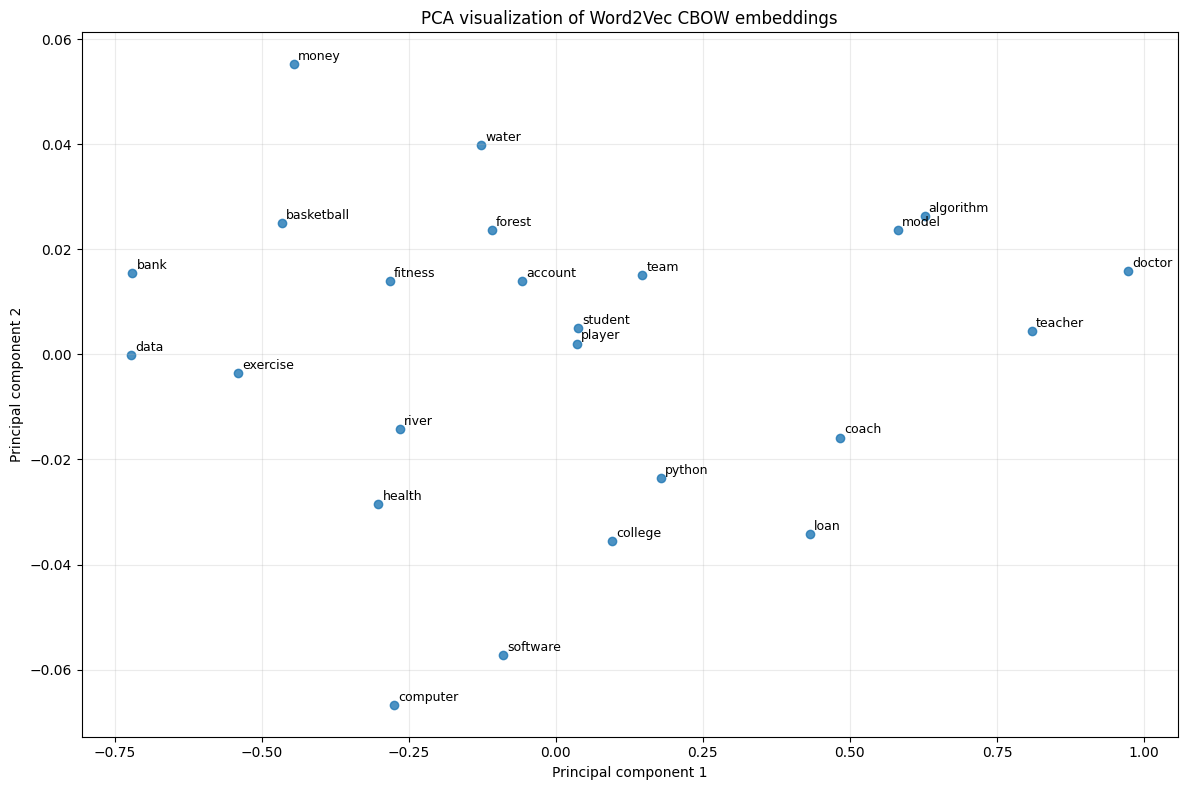

Saved: word2vec_pca_visualization.png


In [11]:
visual_words = [
    "computer", "software", "python", "data", "algorithm", "model",
    "basketball", "player", "coach", "team", "fitness", "exercise",
    "health", "doctor", "bank", "money", "account", "loan",
    "river", "water", "forest", "tree", "student", "college", "teacher",
]
visual_words = [w for w in visual_words if w in word2vec_model.wv.key_to_index]
word_vectors = np.array([word2vec_model.wv[w] for w in visual_words])
coords = PCA(n_components=2, random_state=SEED).fit_transform(word_vectors)

plt.figure(figsize=(12, 8))
plt.scatter(coords[:, 0], coords[:, 1], alpha=0.8)
for i, word in enumerate(visual_words):
    plt.annotate(word, (coords[i, 0], coords[i, 1]), fontsize=9, xytext=(3, 3), textcoords="offset points")
plt.title("PCA visualization of Word2Vec CBOW embeddings")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig("word2vec_pca_visualization.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: word2vec_pca_visualization.png")

## 10. Export files for TensorFlow Embedding Projector

The following cell exports Word2Vec vectors and their token labels in tab-separated files. In TensorFlow Embedding Projector, upload `vectors.tsv` as the data file and `metadata.tsv` as the metadata/labels file. The files are also downloaded as notebook outputs when using the Colab file browser.

In [12]:
export_words = list(word2vec_model.wv.index_to_key[:200])
export_vectors = np.array([word2vec_model.wv[w] for w in export_words])
np.savetxt("vectors.tsv", export_vectors, delimiter="\t", fmt="%.6f")
with open("metadata.tsv", "w", encoding="utf-8") as f:
    f.write("word\n")
    for word in export_words:
        f.write(word + "\n")
print("Saved vectors.tsv with shape", export_vectors.shape)
print("Saved metadata.tsv with", len(export_words), "labels")

Saved vectors.tsv with shape (200, 64)
Saved metadata.tsv with 200 labels


## 11. Consolidated comparison table

| Technique | Type | Context-sensitive? | OOV handling | Strength | Limitation |
|---|---|---|---|---|---|
| One-Hot | Traditional | No | Needs a new dimension/encoding | Simple and interpretable | Very sparse; no semantic similarity by itself |
| Bag of Words | Frequency-based | No | Unknown terms can extend vocabulary | Simple document representation | Ignores word order and context |
| TF-IDF | Frequency-based | No | Depends on fitted vocabulary | Down-weights common terms | Sparse; semantic relations are indirect |
| Word2Vec CBOW | Predictive static | No, one vector per word | Cannot create a learned vector for unseen words | Dense vectors learn distributional similarity | Needs enough text; same word vector in every context |
| GloVe | Global co-occurrence | No | Usually vocabulary-limited | Uses global co-occurrence statistics | Pretrained vectors/corpus choices affect coverage |
| FastText | Predictive + character n-grams | No, word-level static | Can construct vectors using subword n-grams | Often handles rare/unseen spellings better | Generated OOV vectors are not guaranteed to be meaningful |
| Keras Embedding | Trainable neural layer | Depends on model/objective | Needs OOV token/handling strategy | Learnable and task-specific | Needs training data and a suitable objective |
| BERT | Contextual Transformer | Yes | WordPiece tokenization breaks many unknown forms into subwords | Context-dependent word representations | More compute and model memory than simple methods |
| SBERT | Sentence Transformer | Yes at sentence level | Uses Transformer tokenizer | Useful semantic sentence similarity | Larger computational cost than sparse methods |